## What do all of these differences mean for the research question?

-Imports and paths

-Define four pipelines and thresholds

-Define candidate SNP files

-Load candidate counts

-Load Notebook 06 index-SNP summary

-Load Notebook 07 weight summary

-Load Notebook 07 overlap summaries

-Build one master 2×2 table

-Calculate candidate → index retention

-Calculate candidate → final-weight retention

-Calculate GWAS-ancestry contrasts

-Calculate LD-reference-ancestry contrasts

-Calculate matched vs mismatched contrasts

-Calculate descriptive interaction contrasts

-Summarize SNP identity overlap

-Summarize effect-size composition

-Generate integrated figures

-Generate final study-level results tables

-Run final QC and save

## Mount Google Drive

Google Drive is mounted to provide persistent storage for the project files and intermediate results.

Using persistent storage prevents the loss of large reference datasets and computational outputs when the Colab runtime is disconnected or restarted.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## Imports and project paths

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Four completed PRS pipelines
PROJECT_AFR_AFR = Path(
    "/content/drive/MyDrive/PRS_T2D"
)

PROJECT_AFR_EUR = Path(
    "/content/drive/MyDrive/PRS_T2D_A-E"
)

PROJECT_EUR_AFR = Path(
    "/content/drive/MyDrive/PRS_T2D_E-A"
)

PROJECT_EUR_EUR = Path(
    "/content/drive/MyDrive/PRS_T2D_E-E"
)

# P-value thresholds
THRESHOLDS = {
    "P5e-08": 5e-8,
    "P1e-05": 1e-5,
    "P0.0001": 1e-4,
    "P0.001": 1e-3,
    "P0.01": 1e-2,
    "P0.05": 5e-2
}

CHROMOSOMES = list(range(1, 23))

print("Projects, thresholds and chromosomes defined.")

Projects, thresholds and chromosomes defined.


## Define the four pipelines

In [ ]:
PIPELINE_INFO = {
    "AFR-AFR": {
        "GWAS_Ancestry": "AFR",
        "LD_Ancestry": "AFR",
        "Matched": True
    },
    "AFR-EUR": {
        "GWAS_Ancestry": "AFR",
        "LD_Ancestry": "EUR",
        "Matched": False
    },
    "EUR-AFR": {
        "GWAS_Ancestry": "EUR",
        "LD_Ancestry": "AFR",
        "Matched": False
    },
    "EUR-EUR": {
        "GWAS_Ancestry": "EUR",
        "LD_Ancestry": "EUR",
        "Matched": True
    }
}

pipeline_info = pd.DataFrame.from_dict(
    PIPELINE_INFO,
    orient="index"
).reset_index().rename(
    columns={"index": "Pipeline"}
)

display(pipeline_info)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched
0,AFR-AFR,AFR,AFR,True
1,AFR-EUR,AFR,EUR,False
2,EUR-AFR,EUR,AFR,False
3,EUR-EUR,EUR,EUR,True


## Define candidate SNP files

In [ ]:
CANDIDATE_DIRS = {
    "AFR-AFR": PROJECT_AFR_AFR / "results" / "candidate_snps",
    "AFR-EUR": PROJECT_AFR_EUR / "results" / "candidate_snps",
    "EUR-AFR": PROJECT_EUR_AFR / "results" / "candidate_snps",
    "EUR-EUR": PROJECT_EUR_EUR / "results" / "candidate_snps"
}

CANDIDATE_FILENAMES = {
    "AFR-AFR": {
        "P5e-08": "T2D_PheCode250_2_P5e-08.tsv",
        "P1e-05": "T2D_PheCode250_2_P1e-05.tsv",
        "P0.0001": "T2D_PheCode250_2_P0.0001.tsv",
        "P0.001": "T2D_PheCode250_2_P0.001.tsv",
        "P0.01": "T2D_PheCode250_2_P0.01.tsv",
        "P0.05": "T2D_PheCode250_2_P0.05.tsv"
    },

    "AFR-EUR": {
        "P5e-08": "T2D_PheCode250_2_P5e-08.tsv",
        "P1e-05": "T2D_PheCode250_2_P1e-05.tsv",
        "P0.0001": "T2D_PheCode250_2_P0.0001.tsv",
        "P0.001": "T2D_PheCode250_2_P0.001.tsv",
        "P0.01": "T2D_PheCode250_2_P0.01.tsv",
        "P0.05": "T2D_PheCode250_2_P0.05.tsv"
    },

    "EUR-AFR": {
        "P5e-08": "MVP_T2D_Phe_250_2_EUR_P5e-08.tsv",
        "P1e-05": "MVP_T2D_Phe_250_2_EUR_P1e-05.tsv",
        "P0.0001": "MVP_T2D_Phe_250_2_EUR_P0.0001.tsv",
        "P0.001": "MVP_T2D_Phe_250_2_EUR_P0.001.tsv",
        "P0.01": "MVP_T2D_Phe_250_2_EUR_P0.01.tsv",
        "P0.05": "MVP_T2D_Phe_250_2_EUR_P0.05.tsv"
    },

    "EUR-EUR": {
        "P5e-08": "MVP_T2D_Phe_250_2_EUR_P5e-08.tsv",
        "P1e-05": "MVP_T2D_Phe_250_2_EUR_P1e-05.tsv",
        "P0.0001": "MVP_T2D_Phe_250_2_EUR_P0.0001.tsv",
        "P0.001": "MVP_T2D_Phe_250_2_EUR_P0.001.tsv",
        "P0.01": "MVP_T2D_Phe_250_2_EUR_P0.01.tsv",
        "P0.05": "MVP_T2D_Phe_250_2_EUR_P0.05.tsv"
    }
}

## Verify candidate files

In [ ]:
candidate_inventory = []

for pipeline in CANDIDATE_DIRS:
    for threshold in THRESHOLDS:

        candidate_file = (
            CANDIDATE_DIRS[pipeline]
            / CANDIDATE_FILENAMES[pipeline][threshold]
        )

        candidate_inventory.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Path": candidate_file,
            "Exists": candidate_file.exists()
        })

candidate_inventory = pd.DataFrame(candidate_inventory)

print("Expected candidate files:", len(candidate_inventory))
print("Files present:", candidate_inventory["Exists"].sum())
print("Files missing:", (~candidate_inventory["Exists"]).sum())

display(candidate_inventory)

Expected candidate files: 24
Files present: 24
Files missing: 0


,Pipeline,Threshold,Path,Exists
0,AFR-AFR,P5e-08,/content/drive/MyDrive/PRS_T2D/results/candida...,True
1,AFR-AFR,P1e-05,/content/drive/MyDrive/PRS_T2D/results/candida...,True
2,AFR-AFR,P0.0001,/content/drive/MyDrive/PRS_T2D/results/candida...,True
3,AFR-AFR,P0.001,/content/drive/MyDrive/PRS_T2D/results/candida...,True
4,AFR-AFR,P0.01,/content/drive/MyDrive/PRS_T2D/results/candida...,True
5,AFR-AFR,P0.05,/content/drive/MyDrive/PRS_T2D/results/candida...,True
6,AFR-EUR,P5e-08,/content/drive/MyDrive/PRS_T2D_A-E/results/can...,True
7,AFR-EUR,P1e-05,/content/drive/MyDrive/PRS_T2D_A-E/results/can...,True
8,AFR-EUR,P0.0001,/content/drive/MyDrive/PRS_T2D_A-E/results/can...,True
9,AFR-EUR,P0.001,/content/drive/MyDrive/PRS_T2D_A-E/results/can...,True


## Load candidate SNPs

In [ ]:
candidate_data = {}

for pipeline in CANDIDATE_DIRS:

    candidate_data[pipeline] = {}

    for threshold in THRESHOLDS:

        candidate_file = (
            CANDIDATE_DIRS[pipeline]
            / CANDIDATE_FILENAMES[pipeline][threshold]
        )

        df = pd.read_csv(
            candidate_file,
            sep="\t"
        )

        df["SNP"] = (
            df["SNP"]
            .astype(str)
            .str.strip()
        )

        candidate_data[pipeline][threshold] = df

print("All candidate SNP files loaded.")

All candidate SNP files loaded.


## Calculate candidate SNP counts

In [ ]:
candidate_count_records = []

for pipeline in candidate_data:

    for threshold in THRESHOLDS:

        df = candidate_data[pipeline][threshold]

        candidate_count_records.append({
            "Pipeline": pipeline,
            "GWAS_Ancestry": PIPELINE_INFO[pipeline]["GWAS_Ancestry"],
            "LD_Ancestry": PIPELINE_INFO[pipeline]["LD_Ancestry"],
            "Matched": PIPELINE_INFO[pipeline]["Matched"],
            "Threshold": threshold,
            "P_threshold": THRESHOLDS[threshold],
            "Candidate_SNPs": df["SNP"].nunique()
        })

candidate_counts = pd.DataFrame(candidate_count_records)

display(candidate_counts)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched,Threshold,P_threshold,Candidate_SNPs
0,AFR-AFR,AFR,AFR,True,P5e-08,5.000000e-08,27292
1,AFR-AFR,AFR,AFR,True,P1e-05,1.000000e-05,64638
2,AFR-AFR,AFR,AFR,True,P0.0001,1.000000e-04,104274
3,AFR-AFR,AFR,AFR,True,P0.001,1.000000e-03,197201
4,AFR-AFR,AFR,AFR,True,P0.01,1.000000e-02,528446
5,AFR-AFR,AFR,AFR,True,P0.05,5.000000e-02,1500187
6,AFR-EUR,AFR,EUR,False,P5e-08,5.000000e-08,27292
7,AFR-EUR,AFR,EUR,False,P1e-05,1.000000e-05,64638
8,AFR-EUR,AFR,EUR,False,P0.0001,1.000000e-04,104274
9,AFR-EUR,AFR,EUR,False,P0.001,1.000000e-03,197201


## Load LD-clumping summary

In [ ]:
LD_COMPARISON_DIR = Path(
    "/content/drive/MyDrive/"
    "PRS_T2D_comparison/"
    "PRS_LD_Clumping_Comparison"
)

LD_SUMMARY_FILE = (
    LD_COMPARISON_DIR
    / "LD_clumping_summary.tsv"
)

index_summary = pd.read_csv(
    LD_SUMMARY_FILE,
    sep="\t"
)

index_summary = index_summary[
    [
        "Pipeline",
        "Threshold",
        "P_threshold",
        "Index_SNPs"
    ]
]

display(index_summary)

,Pipeline,Threshold,P_threshold,Index_SNPs
0,AFR-AFR,P5e-08,5.000000e-08,1710
1,AFR-AFR,P1e-05,1.000000e-05,4305
2,AFR-AFR,P0.0001,1.000000e-04,7666
3,AFR-AFR,P0.001,1.000000e-03,19691
4,AFR-AFR,P0.01,1.000000e-02,90187
5,AFR-AFR,P0.05,5.000000e-02,357804
6,AFR-EUR,P5e-08,5.000000e-08,633
7,AFR-EUR,P1e-05,1.000000e-05,1636
8,AFR-EUR,P0.0001,1.000000e-04,3302
9,AFR-EUR,P0.001,1.000000e-03,11288


## Combine candidate counts and index counts

In [ ]:
integrated = candidate_counts.merge(
    index_summary,
    on=[
        "Pipeline",
        "Threshold",
        "P_threshold"
    ],
    how="left"
)

display(integrated)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched,Threshold,P_threshold,Candidate_SNPs,Index_SNPs
0,AFR-AFR,AFR,AFR,True,P5e-08,5.000000e-08,27292,1710
1,AFR-AFR,AFR,AFR,True,P1e-05,1.000000e-05,64638,4305
2,AFR-AFR,AFR,AFR,True,P0.0001,1.000000e-04,104274,7666
3,AFR-AFR,AFR,AFR,True,P0.001,1.000000e-03,197201,19691
4,AFR-AFR,AFR,AFR,True,P0.01,1.000000e-02,528446,90187
5,AFR-AFR,AFR,AFR,True,P0.05,5.000000e-02,1500187,357804
6,AFR-EUR,AFR,EUR,False,P5e-08,5.000000e-08,27292,633
7,AFR-EUR,AFR,EUR,False,P1e-05,1.000000e-05,64638,1636
8,AFR-EUR,AFR,EUR,False,P0.0001,1.000000e-04,104274,3302
9,AFR-EUR,AFR,EUR,False,P0.001,1.000000e-03,197201,11288


## Calculate candidate-to-index retention

In [ ]:
integrated["Candidate_to_Index_Retention_pct"] = (
    integrated["Index_SNPs"]
    / integrated["Candidate_SNPs"]
    * 100
)

display(
    integrated[
        [
            "Pipeline",
            "Threshold",
            "Candidate_SNPs",
            "Index_SNPs",
            "Candidate_to_Index_Retention_pct"
        ]
    ]
)

,Pipeline,Threshold,Candidate_SNPs,Index_SNPs,Candidate_to_Index_Retention_pct
0,AFR-AFR,P5e-08,27292,1710,6.265572
1,AFR-AFR,P1e-05,64638,4305,6.660169
2,AFR-AFR,P0.0001,104274,7666,7.351785
3,AFR-AFR,P0.001,197201,19691,9.985243
4,AFR-AFR,P0.01,528446,90187,17.066455
5,AFR-AFR,P0.05,1500187,357804,23.850627
6,AFR-EUR,P5e-08,27292,633,2.319361
7,AFR-EUR,P1e-05,64638,1636,2.531019
8,AFR-EUR,P0.0001,104274,3302,3.166657
9,AFR-EUR,P0.001,197201,11288,5.724109


## Load weight summary

In [ ]:
WEIGHT_COMPARISON_DIR = Path(
    "/content/drive/MyDrive/"
    "PRS_T2D_comparison/"
    "PRS_Weight_Comparison"
)

WEIGHT_SUMMARY_FILE = (
    WEIGHT_COMPARISON_DIR
    / "weight_summary.tsv"
)

weight_summary = pd.read_csv(
    WEIGHT_SUMMARY_FILE,
    sep="\t"
)

display(weight_summary)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Threshold,P_threshold,Weighted_SNPs,Mean_BETA,Median_BETA,SD_BETA,Mean_abs_BETA,Median_abs_BETA,Mean_EAF,Median_EAF,Mean_P,Median_P
0,AFR-AFR,AFR,AFR,P5e-08,5.000000e-08,1710,-0.001799,-0.008834,0.027408,0.019870,0.013268,0.470350,0.46150,5.460369e-09,7.983500e-11
1,AFR-AFR,AFR,AFR,P1e-05,1.000000e-05,4305,-0.000200,-0.006957,0.030929,0.016892,0.010758,0.458686,0.44000,1.710153e-06,2.588000e-07
2,AFR-AFR,AFR,AFR,P0.0001,1.000000e-04,7666,0.000930,0.005967,0.045375,0.019861,0.010097,0.456120,0.42990,2.124280e-05,5.962000e-06
3,AFR-AFR,AFR,AFR,P0.001,1.000000e-03,19691,0.003683,0.005287,0.087090,0.034967,0.010975,0.442335,0.38680,3.116708e-04,2.034000e-04
4,AFR-AFR,AFR,AFR,P0.01,1.000000e-02,90187,0.006830,0.004635,0.153014,0.067797,0.022005,0.424161,0.24420,4.199509e-03,3.919000e-03
5,AFR-AFR,AFR,AFR,P0.05,5.000000e-02,357804,0.003191,0.003933,0.201717,0.087556,0.032159,0.414671,0.07462,2.330717e-02,2.290000e-02
6,AFR-EUR,AFR,EUR,P5e-08,5.000000e-08,633,-0.000194,-0.008636,0.022838,0.017952,0.013163,0.455143,0.42620,5.838452e-09,2.020000e-10
7,AFR-EUR,AFR,EUR,P1e-05,1.000000e-05,1636,-0.001795,-0.006892,0.105258,0.022264,0.011262,0.443716,0.40715,1.746209e-06,3.051000e-07
8,AFR-EUR,AFR,EUR,P0.0001,1.000000e-04,3302,0.003222,0.006184,0.110086,0.038640,0.011292,0.441013,0.39165,2.507497e-05,1.025000e-05
9,AFR-EUR,AFR,EUR,P0.001,1.000000e-03,11288,0.008789,0.005697,0.148353,0.078009,0.019471,0.431396,0.31705,3.762072e-04,3.212000e-04


## Add final weighted SNP counts

In [ ]:
integrated = integrated.merge(
    weight_summary[
        [
            "Pipeline",
            "Threshold",
            "P_threshold",
            "Weighted_SNPs",
            "Mean_BETA",
            "Median_BETA",
            "SD_BETA",
            "Mean_abs_BETA",
            "Median_abs_BETA",
            "Mean_EAF",
            "Median_EAF",
            "Mean_P",
            "Median_P"
        ]
    ],
    on=[
        "Pipeline",
        "Threshold",
        "P_threshold"
    ],
    how="left"
)

display(integrated)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched,Threshold,P_threshold,Candidate_SNPs,Index_SNPs,Candidate_to_Index_Retention_pct,Weighted_SNPs,Mean_BETA,Median_BETA,SD_BETA,Mean_abs_BETA,Median_abs_BETA,Mean_EAF,Median_EAF,Mean_P,Median_P
0,AFR-AFR,AFR,AFR,True,P5e-08,5.000000e-08,27292,1710,6.265572,1710,-0.001799,-0.008834,0.027408,0.019870,0.013268,0.470350,0.46150,5.460369e-09,7.983500e-11
1,AFR-AFR,AFR,AFR,True,P1e-05,1.000000e-05,64638,4305,6.660169,4305,-0.000200,-0.006957,0.030929,0.016892,0.010758,0.458686,0.44000,1.710153e-06,2.588000e-07
2,AFR-AFR,AFR,AFR,True,P0.0001,1.000000e-04,104274,7666,7.351785,7666,0.000930,0.005967,0.045375,0.019861,0.010097,0.456120,0.42990,2.124280e-05,5.962000e-06
3,AFR-AFR,AFR,AFR,True,P0.001,1.000000e-03,197201,19691,9.985243,19691,0.003683,0.005287,0.087090,0.034967,0.010975,0.442335,0.38680,3.116708e-04,2.034000e-04
4,AFR-AFR,AFR,AFR,True,P0.01,1.000000e-02,528446,90187,17.066455,90187,0.006830,0.004635,0.153014,0.067797,0.022005,0.424161,0.24420,4.199509e-03,3.919000e-03
5,AFR-AFR,AFR,AFR,True,P0.05,5.000000e-02,1500187,357804,23.850627,357804,0.003191,0.003933,0.201717,0.087556,0.032159,0.414671,0.07462,2.330717e-02,2.290000e-02
6,AFR-EUR,AFR,EUR,False,P5e-08,5.000000e-08,27292,633,2.319361,633,-0.000194,-0.008636,0.022838,0.017952,0.013163,0.455143,0.42620,5.838452e-09,2.020000e-10
7,AFR-EUR,AFR,EUR,False,P1e-05,1.000000e-05,64638,1636,2.531019,1636,-0.001795,-0.006892,0.105258,0.022264,0.011262,0.443716,0.40715,1.746209e-06,3.051000e-07
8,AFR-EUR,AFR,EUR,False,P0.0001,1.000000e-04,104274,3302,3.166657,3302,0.003222,0.006184,0.110086,0.038640,0.011292,0.441013,0.39165,2.507497e-05,1.025000e-05
9,AFR-EUR,AFR,EUR,False,P0.001,1.000000e-03,197201,11288,5.724109,11288,0.008789,0.005697,0.148353,0.078009,0.019471,0.431396,0.31705,3.762072e-04,3.212000e-04


## Verify the three-stage count chain

In [ ]:
integrated["Index_equals_Weighted"] = (
    integrated["Index_SNPs"]
    == integrated["Weighted_SNPs"]
)

integrated["Weighted_to_Candidate_Retention_pct"] = (
    integrated["Weighted_SNPs"]
    / integrated["Candidate_SNPs"]
    * 100
)

print(
    "All index counts equal weighted-SNP counts:",
    integrated["Index_equals_Weighted"].all()
)

display(
    integrated[
        [
            "Pipeline",
            "Threshold",
            "Candidate_SNPs",
            "Index_SNPs",
            "Weighted_SNPs",
            "Candidate_to_Index_Retention_pct",
            "Weighted_to_Candidate_Retention_pct"
        ]
    ]
)

All index counts equal weighted-SNP counts: True


,Pipeline,Threshold,Candidate_SNPs,Index_SNPs,Weighted_SNPs,Candidate_to_Index_Retention_pct,Weighted_to_Candidate_Retention_pct
0,AFR-AFR,P5e-08,27292,1710,1710,6.265572,6.265572
1,AFR-AFR,P1e-05,64638,4305,4305,6.660169,6.660169
2,AFR-AFR,P0.0001,104274,7666,7666,7.351785,7.351785
3,AFR-AFR,P0.001,197201,19691,19691,9.985243,9.985243
4,AFR-AFR,P0.01,528446,90187,90187,17.066455,17.066455
5,AFR-AFR,P0.05,1500187,357804,357804,23.850627,23.850627
6,AFR-EUR,P5e-08,27292,633,633,2.319361,2.319361
7,AFR-EUR,P1e-05,64638,1636,1636,2.531019,2.531019
8,AFR-EUR,P0.0001,104274,3302,3302,3.166657,3.166657
9,AFR-EUR,P0.001,197201,11288,11288,5.724109,5.724109


## Calculate LD-reference contrasts

In [ ]:
ld_contrast_records = []

for threshold in THRESHOLDS:

    row_afr_afr = integrated[
        (integrated["Pipeline"] == "AFR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    row_afr_eur = integrated[
        (integrated["Pipeline"] == "AFR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    row_eur_afr = integrated[
        (integrated["Pipeline"] == "EUR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    row_eur_eur = integrated[
        (integrated["Pipeline"] == "EUR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    ld_contrast_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],

        "AFR_GWAS_AFR_LD_Index_SNPs":
            row_afr_afr["Index_SNPs"],

        "AFR_GWAS_EUR_LD_Index_SNPs":
            row_afr_eur["Index_SNPs"],

        "AFR_GWAS_LD_difference":
            row_afr_afr["Index_SNPs"]
            - row_afr_eur["Index_SNPs"],

        "EUR_GWAS_AFR_LD_Index_SNPs":
            row_eur_afr["Index_SNPs"],

        "EUR_GWAS_EUR_LD_Index_SNPs":
            row_eur_eur["Index_SNPs"],

        "EUR_GWAS_LD_difference":
            row_eur_afr["Index_SNPs"]
            - row_eur_eur["Index_SNPs"]
    })

ld_contrasts = pd.DataFrame(ld_contrast_records)

display(ld_contrasts)

,Threshold,P_threshold,AFR_GWAS_AFR_LD_Index_SNPs,AFR_GWAS_EUR_LD_Index_SNPs,AFR_GWAS_LD_difference,EUR_GWAS_AFR_LD_Index_SNPs,EUR_GWAS_EUR_LD_Index_SNPs,EUR_GWAS_LD_difference
0,P5e-08,5.000000e-08,1710,633,1077,4944,2063,2881
1,P1e-05,1.000000e-05,4305,1636,2669,16558,9216,7342
2,P0.0001,1.000000e-04,7666,3302,4364,37511,25465,12046
3,P0.001,1.000000e-03,19691,11288,8403,107335,83925,23410
4,P0.01,1.000000e-02,90187,74325,15862,364262,319256,45006
5,P0.05,5.000000e-02,357804,358128,-324,920240,842495,77745


## Calculate GWAS-ancestry contrasts

In [ ]:
gwas_contrast_records = []

for threshold in THRESHOLDS:

    afr_afr = integrated[
        (integrated["Pipeline"] == "AFR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    afr_eur = integrated[
        (integrated["Pipeline"] == "AFR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_afr = integrated[
        (integrated["Pipeline"] == "EUR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_eur = integrated[
        (integrated["Pipeline"] == "EUR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    gwas_contrast_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],

        "AFR_GWAS_AFR_LD_Index_SNPs":
            afr_afr["Index_SNPs"],

        "EUR_GWAS_AFR_LD_Index_SNPs":
            eur_afr["Index_SNPs"],

        "GWAS_difference_under_AFR_LD":
            eur_afr["Index_SNPs"]
            - afr_afr["Index_SNPs"],

        "AFR_GWAS_EUR_LD_Index_SNPs":
            afr_eur["Index_SNPs"],

        "EUR_GWAS_EUR_LD_Index_SNPs":
            eur_eur["Index_SNPs"],

        "GWAS_difference_under_EUR_LD":
            eur_eur["Index_SNPs"]
            - afr_eur["Index_SNPs"]
    })

gwas_contrasts = pd.DataFrame(gwas_contrast_records)

display(gwas_contrasts)

,Threshold,P_threshold,AFR_GWAS_AFR_LD_Index_SNPs,EUR_GWAS_AFR_LD_Index_SNPs,GWAS_difference_under_AFR_LD,AFR_GWAS_EUR_LD_Index_SNPs,EUR_GWAS_EUR_LD_Index_SNPs,GWAS_difference_under_EUR_LD
0,P5e-08,5.000000e-08,1710,4944,3234,633,2063,1430
1,P1e-05,1.000000e-05,4305,16558,12253,1636,9216,7580
2,P0.0001,1.000000e-04,7666,37511,29845,3302,25465,22163
3,P0.001,1.000000e-03,19691,107335,87644,11288,83925,72637
4,P0.01,1.000000e-02,90187,364262,274075,74325,319256,244931
5,P0.05,5.000000e-02,357804,920240,562436,358128,842495,484367


## Calculate matched versus mismatched configurations

In [ ]:
matched_contrast_records = []

for threshold in THRESHOLDS:

    afr_afr = integrated[
        (integrated["Pipeline"] == "AFR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    afr_eur = integrated[
        (integrated["Pipeline"] == "AFR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_afr = integrated[
        (integrated["Pipeline"] == "EUR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_eur = integrated[
        (integrated["Pipeline"] == "EUR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    matched_mean = (
        afr_afr["Index_SNPs"]
        + eur_eur["Index_SNPs"]
    ) / 2

    mismatched_mean = (
        afr_eur["Index_SNPs"]
        + eur_afr["Index_SNPs"]
    ) / 2

    matched_contrast_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],
        "Matched_mean_Index_SNPs": matched_mean,
        "Mismatched_mean_Index_SNPs": mismatched_mean,
        "Matched_minus_Mismatched":
            matched_mean - mismatched_mean
    })

matched_contrasts = pd.DataFrame(
    matched_contrast_records
)

display(matched_contrasts)

,Threshold,P_threshold,Matched_mean_Index_SNPs,Mismatched_mean_Index_SNPs,Matched_minus_Mismatched
0,P5e-08,5.000000e-08,1886.5,2788.5,-902.0
1,P1e-05,1.000000e-05,6760.5,9097.0,-2336.5
2,P0.0001,1.000000e-04,16565.5,20406.5,-3841.0
3,P0.001,1.000000e-03,51808.0,59311.5,-7503.5
4,P0.01,1.000000e-02,204721.5,219293.5,-14572.0
5,P0.05,5.000000e-02,600149.5,639184.0,-39034.5


## Calculate the descriptive interaction contrast

In [ ]:
interaction_records = []

for threshold in THRESHOLDS:

    afr_afr = integrated[
        (integrated["Pipeline"] == "AFR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    afr_eur = integrated[
        (integrated["Pipeline"] == "AFR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_afr = integrated[
        (integrated["Pipeline"] == "EUR-AFR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    eur_eur = integrated[
        (integrated["Pipeline"] == "EUR-EUR") &
        (integrated["Threshold"] == threshold)
    ].iloc[0]

    ld_effect_afr = (
        afr_afr["Index_SNPs"]
        - afr_eur["Index_SNPs"]
    )

    ld_effect_eur = (
        eur_afr["Index_SNPs"]
        - eur_eur["Index_SNPs"]
    )

    interaction = (
        ld_effect_afr
        - ld_effect_eur
    )

    interaction_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],
        "LD_effect_with_AFR_GWAS": ld_effect_afr,
        "LD_effect_with_EUR_GWAS": ld_effect_eur,
        "Descriptive_interaction":
            interaction
    })

interaction_summary = pd.DataFrame(
    interaction_records
)

display(interaction_summary)

,Threshold,P_threshold,LD_effect_with_AFR_GWAS,LD_effect_with_EUR_GWAS,Descriptive_interaction
0,P5e-08,5.000000e-08,1077,2881,-1804
1,P1e-05,1.000000e-05,2669,7342,-4673
2,P0.0001,1.000000e-04,4364,12046,-7682
3,P0.001,1.000000e-03,8403,23410,-15007
4,P0.01,1.000000e-02,15862,45006,-29144
5,P0.05,5.000000e-02,-324,77745,-78069


## Candidate-stage LD effect check

In [ ]:
candidate_ld_check = candidate_counts.pivot(
    index="Threshold",
    columns="Pipeline",
    values="Candidate_SNPs"
)

candidate_ld_check["AFR_GWAS_LD_difference"] = (
    candidate_ld_check["AFR-AFR"]
    - candidate_ld_check["AFR-EUR"]
)

candidate_ld_check["EUR_GWAS_LD_difference"] = (
    candidate_ld_check["EUR-AFR"]
    - candidate_ld_check["EUR-EUR"]
)

display(candidate_ld_check)

Pipeline,AFR-AFR,AFR-EUR,EUR-AFR,EUR-EUR,AFR_GWAS_LD_difference,EUR_GWAS_LD_difference
Threshold,,,,,,
P0.0001,104274,104274,274975,274975,0,0
P0.001,197201,197201,555660,555660,0,0
P0.01,528446,528446,1396298,1396298,0,0
P0.05,1500187,1500187,3066477,3066477,0,0
P1e-05,64638,64638,161236,161236,0,0
P5e-08,27292,27292,66996,66996,0,0


# Plot the entire PRS construction process

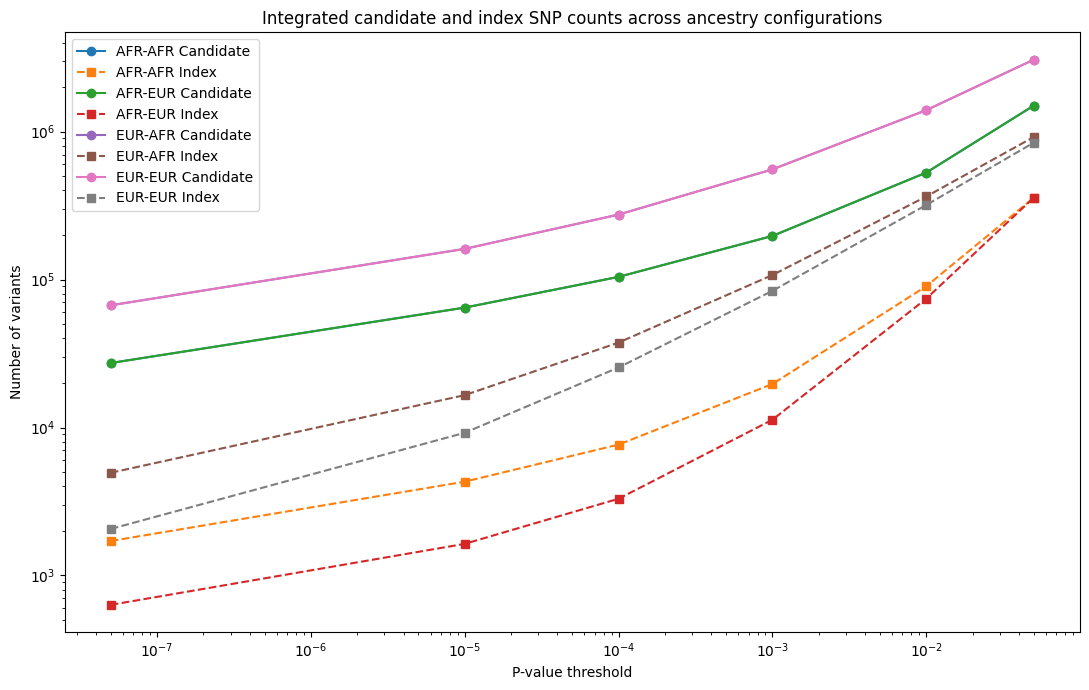

In [ ]:
plt.figure(figsize=(11, 7))

for pipeline in integrated["Pipeline"].unique():

    subset = integrated[
        integrated["Pipeline"] == pipeline
    ].sort_values("P_threshold")

    plt.plot(
        subset["P_threshold"],
        subset["Candidate_SNPs"],
        marker="o",
        label=f"{pipeline} Candidate"
    )

    plt.plot(
        subset["P_threshold"],
        subset["Index_SNPs"],
        marker="s",
        linestyle="--",
        label=f"{pipeline} Index"
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("P-value threshold")
plt.ylabel("Number of variants")
plt.title(
    "Integrated candidate and index SNP counts across ancestry configurations"
)

plt.legend()
plt.tight_layout()
plt.show()

## Plot retention

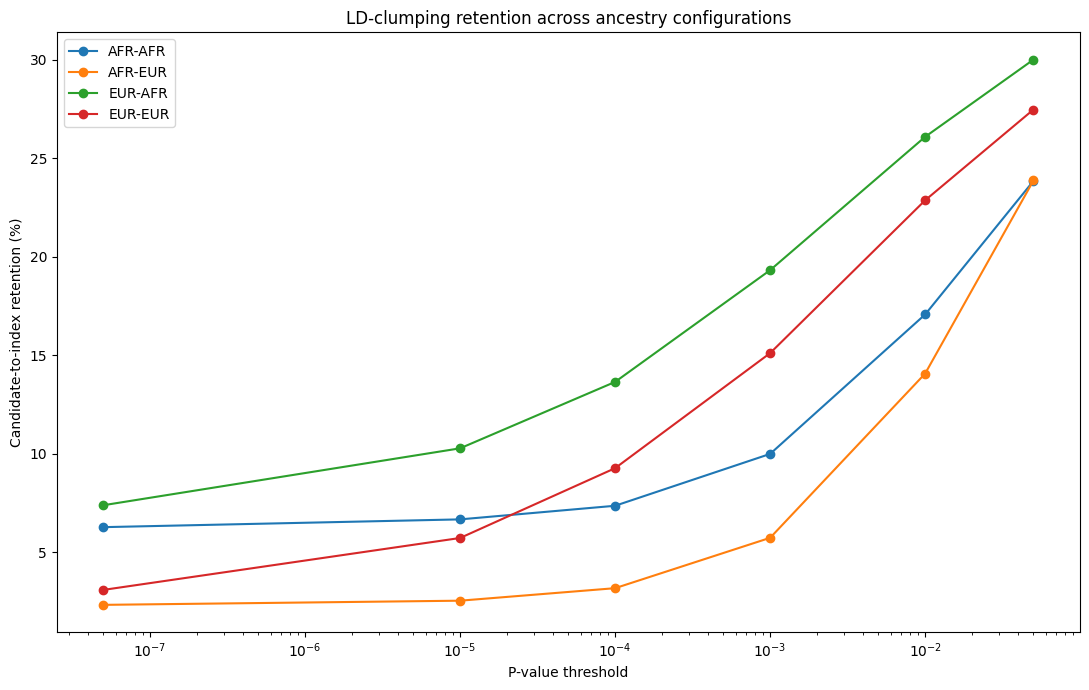

In [ ]:
plt.figure(figsize=(11, 7))

for pipeline in integrated["Pipeline"].unique():

    subset = integrated[
        integrated["Pipeline"] == pipeline
    ].sort_values("P_threshold")

    plt.plot(
        subset["P_threshold"],
        subset["Candidate_to_Index_Retention_pct"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")

plt.xlabel("P-value threshold")
plt.ylabel("Candidate-to-index retention (%)")
plt.title(
    "LD-clumping retention across ancestry configurations"
)

plt.legend()
plt.tight_layout()
plt.show()

## Plot the four-way index-SNP comparison

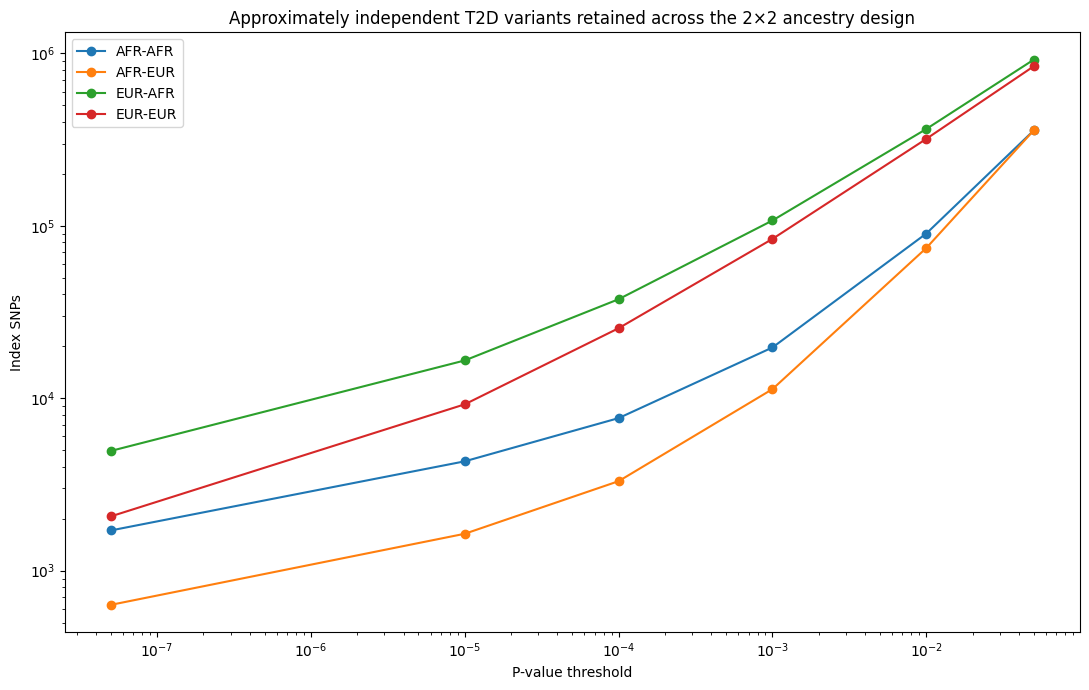

In [ ]:
plt.figure(figsize=(11, 7))

for pipeline in integrated["Pipeline"].unique():

    subset = integrated[
        integrated["Pipeline"] == pipeline
    ].sort_values("P_threshold")

    plt.plot(
        subset["P_threshold"],
        subset["Index_SNPs"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("P-value threshold")
plt.ylabel("Index SNPs")
plt.title(
    "Approximately independent T2D variants retained across the 2×2 ancestry design"
)

plt.legend()
plt.tight_layout()
plt.show()

## Plot final weighted-SNP counts

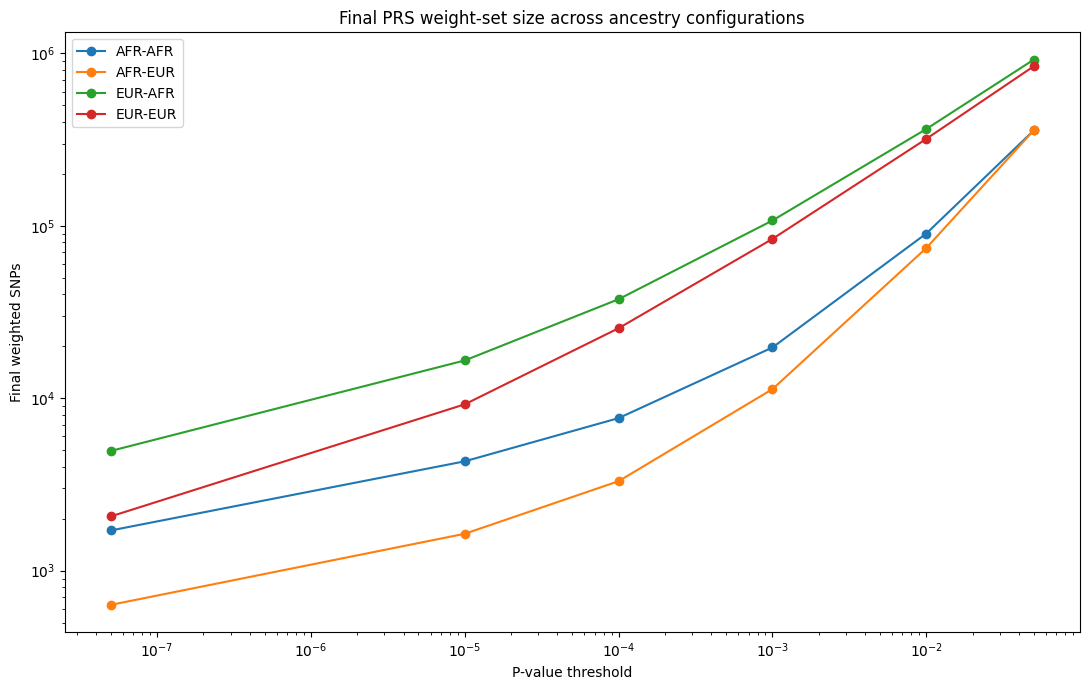

In [ ]:
plt.figure(figsize=(11, 7))

for pipeline in integrated["Pipeline"].unique():

    subset = integrated[
        integrated["Pipeline"] == pipeline
    ].sort_values("P_threshold")

    plt.plot(
        subset["P_threshold"],
        subset["Weighted_SNPs"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("P-value threshold")
plt.ylabel("Final weighted SNPs")
plt.title(
    "Final PRS weight-set size across ancestry configurations"
)

plt.legend()
plt.tight_layout()
plt.show()

## Integrate effect-size composition

In [ ]:
beta_integrated = integrated[
    [
        "Pipeline",
        "GWAS_Ancestry",
        "LD_Ancestry",
        "Matched",
        "Threshold",
        "P_threshold",
        "Weighted_SNPs",
        "Mean_BETA",
        "Median_BETA",
        "SD_BETA",
        "Mean_abs_BETA",
        "Median_abs_BETA"
    ]
].copy()

display(beta_integrated)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched,Threshold,P_threshold,Weighted_SNPs,Mean_BETA,Median_BETA,SD_BETA,Mean_abs_BETA,Median_abs_BETA
0,AFR-AFR,AFR,AFR,True,P5e-08,5.000000e-08,1710,-0.001799,-0.008834,0.027408,0.019870,0.013268
1,AFR-AFR,AFR,AFR,True,P1e-05,1.000000e-05,4305,-0.000200,-0.006957,0.030929,0.016892,0.010758
2,AFR-AFR,AFR,AFR,True,P0.0001,1.000000e-04,7666,0.000930,0.005967,0.045375,0.019861,0.010097
3,AFR-AFR,AFR,AFR,True,P0.001,1.000000e-03,19691,0.003683,0.005287,0.087090,0.034967,0.010975
4,AFR-AFR,AFR,AFR,True,P0.01,1.000000e-02,90187,0.006830,0.004635,0.153014,0.067797,0.022005
5,AFR-AFR,AFR,AFR,True,P0.05,5.000000e-02,357804,0.003191,0.003933,0.201717,0.087556,0.032159
6,AFR-EUR,AFR,EUR,False,P5e-08,5.000000e-08,633,-0.000194,-0.008636,0.022838,0.017952,0.013163
7,AFR-EUR,AFR,EUR,False,P1e-05,1.000000e-05,1636,-0.001795,-0.006892,0.105258,0.022264,0.011262
8,AFR-EUR,AFR,EUR,False,P0.0001,1.000000e-04,3302,0.003222,0.006184,0.110086,0.038640,0.011292
9,AFR-EUR,AFR,EUR,False,P0.001,1.000000e-03,11288,0.008789,0.005697,0.148353,0.078009,0.019471


## Load effect-direction summary

In [ ]:
EFFECT_DIRECTION_FILE = (
    WEIGHT_COMPARISON_DIR
    / "effect_direction_summary.tsv"
)

effect_direction = pd.read_csv(
    EFFECT_DIRECTION_FILE,
    sep="\t"
)

display(effect_direction)

,Pipeline,Threshold,Positive_BETA,Negative_BETA,Zero_BETA,Positive_pct,Negative_pct
0,AFR-AFR,P5e-08,802,908,0,46.900585,53.099415
1,AFR-AFR,P1e-05,2115,2190,0,49.128920,50.871080
2,AFR-AFR,P0.0001,3835,3831,0,50.026089,49.973911
3,AFR-AFR,P0.001,10057,9634,0,51.074095,48.925905
4,AFR-AFR,P0.01,47240,42947,0,52.380055,47.619945
5,AFR-AFR,P0.05,185498,172306,0,51.843467,48.156533
6,AFR-EUR,P5e-08,307,326,0,48.499210,51.500790
7,AFR-EUR,P1e-05,813,823,0,49.694377,50.305623
8,AFR-EUR,P0.0001,1676,1626,0,50.757117,49.242883
9,AFR-EUR,P0.001,5917,5371,0,52.418498,47.581502


# Build final integrated results table

In [ ]:
final_integrated_results = integrated[
    [
        "Pipeline",
        "GWAS_Ancestry",
        "LD_Ancestry",
        "Matched",
        "Threshold",
        "P_threshold",
        "Candidate_SNPs",
        "Index_SNPs",
        "Weighted_SNPs",
        "Candidate_to_Index_Retention_pct",
        "Mean_BETA",
        "Median_BETA",
        "SD_BETA",
        "Mean_abs_BETA",
        "Median_abs_BETA",
        "Mean_EAF",
        "Median_EAF",
        "Mean_P",
        "Median_P"
    ]
].copy()

display(final_integrated_results)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Matched,Threshold,P_threshold,Candidate_SNPs,Index_SNPs,Weighted_SNPs,Candidate_to_Index_Retention_pct,Mean_BETA,Median_BETA,SD_BETA,Mean_abs_BETA,Median_abs_BETA,Mean_EAF,Median_EAF,Mean_P,Median_P
0,AFR-AFR,AFR,AFR,True,P5e-08,5.000000e-08,27292,1710,1710,6.265572,-0.001799,-0.008834,0.027408,0.019870,0.013268,0.470350,0.46150,5.460369e-09,7.983500e-11
1,AFR-AFR,AFR,AFR,True,P1e-05,1.000000e-05,64638,4305,4305,6.660169,-0.000200,-0.006957,0.030929,0.016892,0.010758,0.458686,0.44000,1.710153e-06,2.588000e-07
2,AFR-AFR,AFR,AFR,True,P0.0001,1.000000e-04,104274,7666,7666,7.351785,0.000930,0.005967,0.045375,0.019861,0.010097,0.456120,0.42990,2.124280e-05,5.962000e-06
3,AFR-AFR,AFR,AFR,True,P0.001,1.000000e-03,197201,19691,19691,9.985243,0.003683,0.005287,0.087090,0.034967,0.010975,0.442335,0.38680,3.116708e-04,2.034000e-04
4,AFR-AFR,AFR,AFR,True,P0.01,1.000000e-02,528446,90187,90187,17.066455,0.006830,0.004635,0.153014,0.067797,0.022005,0.424161,0.24420,4.199509e-03,3.919000e-03
5,AFR-AFR,AFR,AFR,True,P0.05,5.000000e-02,1500187,357804,357804,23.850627,0.003191,0.003933,0.201717,0.087556,0.032159,0.414671,0.07462,2.330717e-02,2.290000e-02
6,AFR-EUR,AFR,EUR,False,P5e-08,5.000000e-08,27292,633,633,2.319361,-0.000194,-0.008636,0.022838,0.017952,0.013163,0.455143,0.42620,5.838452e-09,2.020000e-10
7,AFR-EUR,AFR,EUR,False,P1e-05,1.000000e-05,64638,1636,1636,2.531019,-0.001795,-0.006892,0.105258,0.022264,0.011262,0.443716,0.40715,1.746209e-06,3.051000e-07
8,AFR-EUR,AFR,EUR,False,P0.0001,1.000000e-04,104274,3302,3302,3.166657,0.003222,0.006184,0.110086,0.038640,0.011292,0.441013,0.39165,2.507497e-05,1.025000e-05
9,AFR-EUR,AFR,EUR,False,P0.001,1.000000e-03,197201,11288,11288,5.724109,0.008789,0.005697,0.148353,0.078009,0.019471,0.431396,0.31705,3.762072e-04,3.212000e-04


## Create a compact study-level summary

In [ ]:
study_summary_records = []

for threshold in THRESHOLDS:

    subset = integrated[
        integrated["Threshold"] == threshold
    ]

    study_summary_records.append({
        "Threshold": threshold,
        "P_threshold": THRESHOLDS[threshold],

        "AFR_AFR_Candidates":
            subset.loc[
                subset["Pipeline"] == "AFR-AFR",
                "Candidate_SNPs"
            ].iloc[0],

        "AFR_EUR_Candidates":
            subset.loc[
                subset["Pipeline"] == "AFR-EUR",
                "Candidate_SNPs"
            ].iloc[0],

        "EUR_AFR_Candidates":
            subset.loc[
                subset["Pipeline"] == "EUR-AFR",
                "Candidate_SNPs"
            ].iloc[0],

        "EUR_EUR_Candidates":
            subset.loc[
                subset["Pipeline"] == "EUR-EUR",
                "Candidate_SNPs"
            ].iloc[0],

        "AFR_AFR_Index":
            subset.loc[
                subset["Pipeline"] == "AFR-AFR",
                "Index_SNPs"
            ].iloc[0],

        "AFR_EUR_Index":
            subset.loc[
                subset["Pipeline"] == "AFR-EUR",
                "Index_SNPs"
            ].iloc[0],

        "EUR_AFR_Index":
            subset.loc[
                subset["Pipeline"] == "EUR-AFR",
                "Index_SNPs"
            ].iloc[0],

        "EUR_EUR_Index":
            subset.loc[
                subset["Pipeline"] == "EUR-EUR",
                "Index_SNPs"
            ].iloc[0]
    })

study_summary = pd.DataFrame(
    study_summary_records
)

display(study_summary)

,Threshold,P_threshold,AFR_AFR_Candidates,AFR_EUR_Candidates,EUR_AFR_Candidates,EUR_EUR_Candidates,AFR_AFR_Index,AFR_EUR_Index,EUR_AFR_Index,EUR_EUR_Index
0,P5e-08,5.000000e-08,27292,27292,66996,66996,1710,633,4944,2063
1,P1e-05,1.000000e-05,64638,64638,161236,161236,4305,1636,16558,9216
2,P0.0001,1.000000e-04,104274,104274,274975,274975,7666,3302,37511,25465
3,P0.001,1.000000e-03,197201,197201,555660,555660,19691,11288,107335,83925
4,P0.01,1.000000e-02,528446,528446,1396298,1396298,90187,74325,364262,319256
5,P0.05,5.000000e-02,1500187,1500187,3066477,3066477,357804,358128,920240,842495


# Save outputs

In [ ]:
COMPARISON_DIR_08 = Path(
    "/content/drive/MyDrive/"
    "PRS_T2D_comparison/"
    "PRS_Integrated_Ancestry_Comparison"
)

COMPARISON_DIR_08.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR_08 = (
    COMPARISON_DIR_08 / "figures"
)

FIGURE_DIR_08.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Notebook 08 output directory:",
    COMPARISON_DIR_08
)

Notebook 08 output directory: /content/drive/MyDrive/PRS_T2D_comparison/PRS_Integrated_Ancestry_Comparison


In [ ]:
candidate_counts.to_csv(
    COMPARISON_DIR_08 / "candidate_counts.tsv",
    sep="\t",
    index=False
)

integrated.to_csv(
    COMPARISON_DIR_08 / "integrated_prs_construction_summary.tsv",
    sep="\t",
    index=False
)

ld_contrasts.to_csv(
    COMPARISON_DIR_08 / "LD_reference_contrasts.tsv",
    sep="\t",
    index=False
)

gwas_contrasts.to_csv(
    COMPARISON_DIR_08 / "GWAS_ancestry_contrasts.tsv",
    sep="\t",
    index=False
)

matched_contrasts.to_csv(
    COMPARISON_DIR_08 / "matched_vs_mismatched.tsv",
    sep="\t",
    index=False
)

interaction_summary.to_csv(
    COMPARISON_DIR_08 / "descriptive_interaction_contrasts.tsv",
    sep="\t",
    index=False
)

candidate_ld_check.to_csv(
    COMPARISON_DIR_08 / "candidate_stage_LD_check.tsv",
    sep="\t"
)

beta_integrated.to_csv(
    COMPARISON_DIR_08 / "integrated_BETA_summary.tsv",
    sep="\t",
    index=False
)

effect_direction.to_csv(
    COMPARISON_DIR_08 / "integrated_effect_direction.tsv",
    sep="\t",
    index=False
)

final_integrated_results.to_csv(
    COMPARISON_DIR_08 / "final_integrated_results.tsv",
    sep="\t",
    index=False
)

study_summary.to_csv(
    COMPARISON_DIR_08 / "study_level_summary.tsv",
    sep="\t",
    index=False
)

print("Notebook 08 tables saved.")

Notebook 08 tables saved.


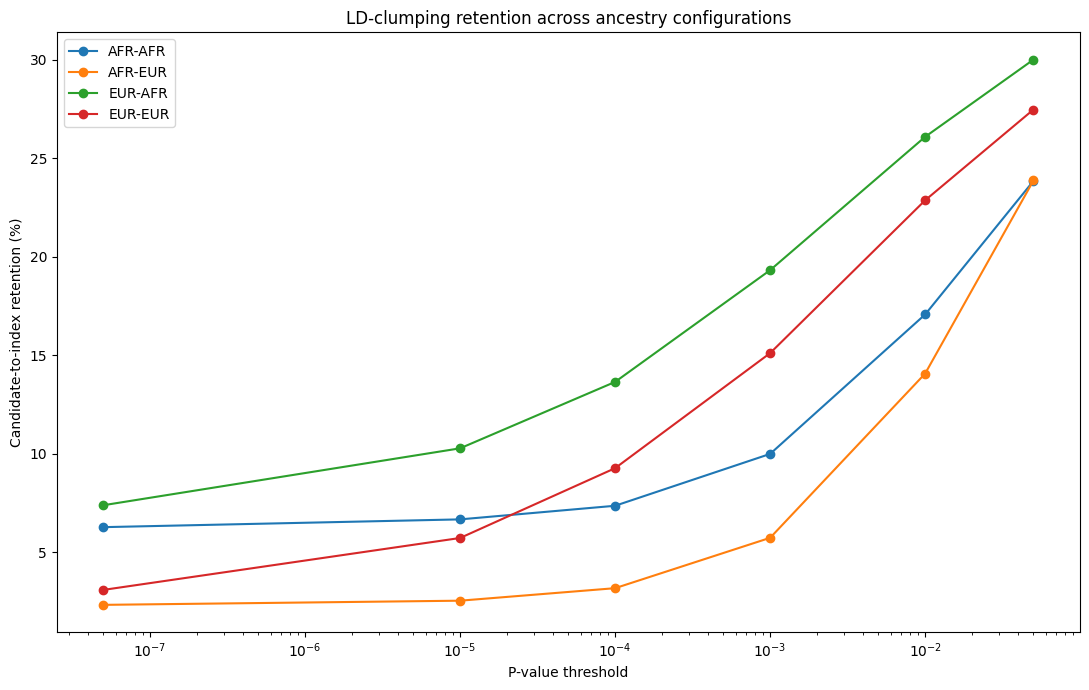

In [ ]:
plt.figure(figsize=(11, 7))

for pipeline in integrated["Pipeline"].unique():

    subset = integrated[
        integrated["Pipeline"] == pipeline
    ].sort_values("P_threshold")

    plt.plot(
        subset["P_threshold"],
        subset["Candidate_to_Index_Retention_pct"],
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Candidate-to-index retention (%)")
plt.title(
    "LD-clumping retention across ancestry configurations"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR_08 / "candidate_to_index_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# FINAL QC

In [ ]:
print("Final QC")
print()

print(
    "Candidate files complete:",
    candidate_inventory["Exists"].all()
)

print(
    "Candidate-to-index counts available:",
    integrated["Index_SNPs"].notna().all()
)

print(
    "Weight counts available:",
    integrated["Weighted_SNPs"].notna().all()
)

print(
    "Index counts equal weighted counts:",
    integrated["Index_equals_Weighted"].all()
)

print(
    "Candidate-stage LD differences are zero:",
    (
        candidate_ld_check["AFR_GWAS_LD_difference"].eq(0).all()
        and
        candidate_ld_check["EUR_GWAS_LD_difference"].eq(0).all()
    )
)

print()
print("Integration complete.")

Final QC

Candidate files complete: True
Candidate-to-index counts available: True
Weight counts available: True
Index counts equal weighted counts: True
Candidate-stage LD differences are zero: True

Integration complete.
